In [1]:
import numpy as np
import pandas as pd
from matplotlib import rc, rcParams
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
import textwrap
from scipy.stats import dunnett, levene, bartlett, tukey_hsd, kruskal
from sklearn.cluster import KMeans
from pathlib import Path

In [2]:
path2figs = Path("figs")
path2figs.mkdir(parents=True, exist_ok=True)
path2stats = "/mnt/cephfs/mir/jcaicedo/projects/de/movies/analysis/results/combined_dataframe.csv"

In [3]:
# Load dataframe, restrict to only green cells:
df = pd.read_csv(path2stats)
_drop_cols = ['color', 'red', 'green', 'entropy', 'parent', 'intensity', 'x_cm', 'y_cm', 'dx', 'dy', 'd_total']
df = df[df['color'] == 'g'].drop(columns=_drop_cols).reset_index(drop=True)

df = df[df['area'] >= 100].reset_index(drop=True)
_drop_cols = ['area']
df = df.drop(columns=_drop_cols).reset_index(drop=True)

In [4]:
df_n_green_time = pd.DataFrame()
df_n_frames = df.groupby(['vclass', 'vidx'])['frame'].nunique().reset_index(name='n_frames')
for idx, row in df_n_frames.iterrows():
    vclass, vidx, n_frames = row.vclass, row.vidx, row.n_frames

    row = []
    n_green_max = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= n_frames)]['label'].nunique()
    for frame in range(n_frames):
        n_green_in_frame = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame == frame)]['label'].nunique()
        n_green_cdf = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= frame)]['label'].nunique() / n_green_max

        row.append({
            'vclass': vclass, 
            'vidx': vidx, 
            'frame': frame, 
            'n_green_in_frame': n_green_in_frame, 
            'n_green_cdf': n_green_cdf})
    # end for

    df_n_green_time = pd.concat([df_n_green_time, pd.DataFrame(row)])
# end for

df_n_green_time['n_green_pdf'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_cdf'].transform(lambda x: x.diff()).fillna(0)
df_n_green_time['n_green_pdf'] = (
    df_n_green_time.groupby(['vclass', 'vidx'])['n_green_pdf']
    .transform(lambda x: x / x.sum())
)

df_n_green_time['delta_n_green_in_frame'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_in_frame'].transform(lambda x: x - x.iloc[0]).fillna(0)

In [5]:
path2out = "/home/MORGRIDGE/gbonner/gbonner/Repositories/heart-explant/figs/pulse/pulse.csv"
df_n_green_time.drop(columns=['n_green_cdf', 'n_green_pdf']) \
    .sort_values(by=['vclass', 'vidx', 'frame']) \
    .reset_index(drop=True) \
    .to_csv(path2out, index_label=None)

In [6]:
df_n_green_time_corrected = pd.read_csv("/home/MORGRIDGE/gbonner/gbonner/Repositories/heart-explant/figs/pulse/pulse_times.csv")

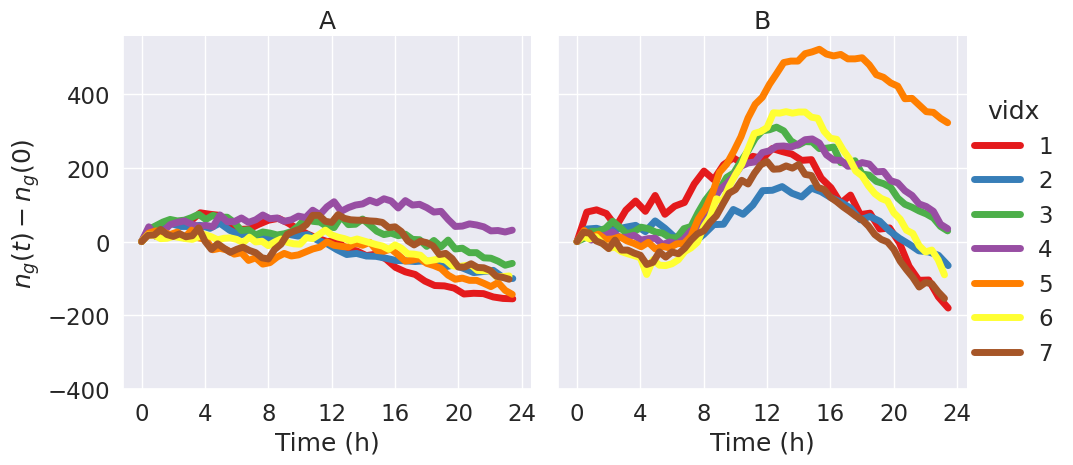

In [7]:
def _():
    sns.set_theme(font_scale=1.5)
    g = sns.relplot(data=df_n_green_time_corrected, kind='line', 
                x='time (h)', y='delta_n_green_in_frame', 
                col='vclass', col_order=['A', 'B'],
                hue='vidx',
                lw=5,
                palette='Set1')

    # set custom col titles
    col_titles = [
        "A", 
        "B"
    ]
    for ax, title in zip(g.axes.flat, col_titles):
        ax.set_title(title)
    g.set(xlabel='Time (h)', ylabel=r'$n_g(t) - n_g(0)$')
    plt.xticks([0, 4, 8, 12, 16, 20, 24])
    plt.yticks([-400, -200, 0, 200, 400])

    plt.savefig(path2figs / 'n_alive_pulse_timecorr.pdf')

    return g


_()